<a href="https://colab.research.google.com/github/Prasun6736/Natural_Language_Processing/blob/main/Flowers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np


In [ ]:
# Training data: sentence and class label (1 = sports, 0 = reading/studying)
data = [
    ["I enjoy playing football", 1],
    ["I like reading books", 0],
    ["I love playing football with my friends", 1],
    ["I prefer reading books at home", 0],
    ["I enjoy playing sports", 1],
    ["I like studying", 0],
    ["I am passionate about football", 1],
    ["I enjoy reading", 0]
]

mystery_text = "I like playing football"

# Convert sentences into lowercase tokens
tokenized_data = []
for sentence, label in data:
    tokens = sentence.lower().split()
    tokenized_data.append([tokens, label])

print("Tokenized data:")
print(tokenized_data)

# Create a vocabulary from all training sentences
vocabulary = sorted({
    word
    for tokens, label in tokenized_data
    for word in tokens
})

# Assign a unique ID to each word
word_to_id = {word: i for i, word in enumerate(vocabulary)}

print("\nVocabulary:", vocabulary)
print("Word to ID:", word_to_id)
print("Vocabulary size:", len(vocabulary))

# Convert each sentence into a bag-of-words binary vector
X = []
y = []

for tokens, label in tokenized_data:
    vector = np.zeros(len(vocabulary), dtype=float)
    for word in tokens:
        vector[word_to_id[word]] = 1.0
    X.append(vector)
    y.append(label)

X = np.array(X, dtype=float)
y = np.array(y, dtype=float).reshape(-1, 1)

print("\nVector representations of training sentences:")
print(X)
print("\nFeature matrix shape:", X.shape)
print("Labels:", y.flatten().astype(int))


Tokenized data:
[[['i', 'enjoy', 'playing', 'football'], 1], [['i', 'like', 'reading', 'books'], 0], [['i', 'love', 'playing', 'football', 'with', 'my', 'friends'], 1], [['i', 'prefer', 'reading', 'books', 'at', 'home'], 0], [['i', 'enjoy', 'playing', 'sports'], 1], [['i', 'like', 'studying'], 0], [['i', 'am', 'passionate', 'about', 'football'], 1], [['i', 'enjoy', 'reading'], 0]]

Vocabulary: ['about', 'am', 'at', 'books', 'enjoy', 'football', 'friends', 'home', 'i', 'like', 'love', 'my', 'passionate', 'playing', 'prefer', 'reading', 'sports', 'studying', 'with']
Word to ID: {'about': 0, 'am': 1, 'at': 2, 'books': 3, 'enjoy': 4, 'football': 5, 'friends': 6, 'home': 7, 'i': 8, 'like': 9, 'love': 10, 'my': 11, 'passionate': 12, 'playing': 13, 'prefer': 14, 'reading': 15, 'sports': 16, 'studying': 17, 'with': 18}
Vocabulary size: 19

Vector representations of training sentences:
[[0. 0. 0. 0. 1. 1. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 

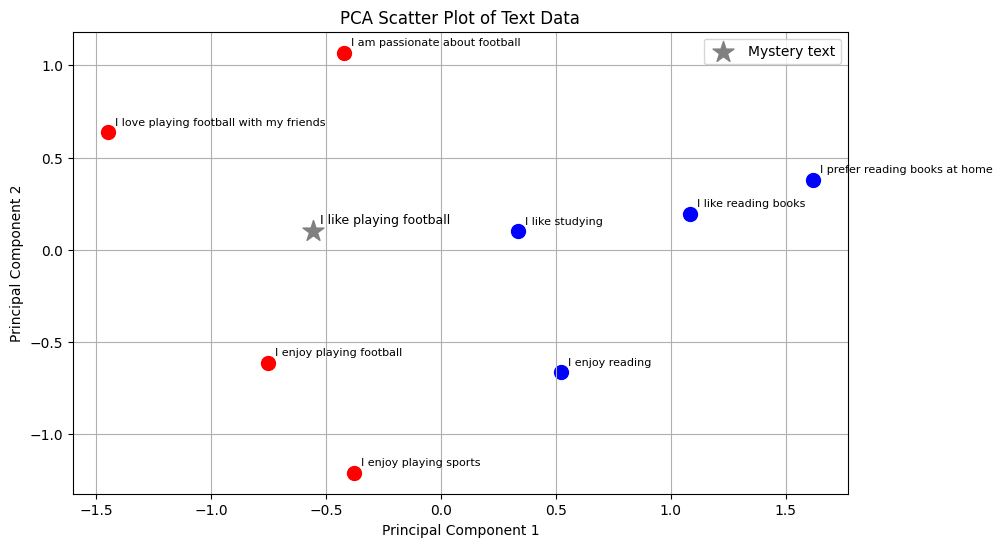

In [ ]:
# Scatter plot of the text data
# The bag-of-words vectors have many dimensions, so PCA projects them into 2D.
# The plot uses the original sentence labels: blue = class 0, red = class 1.

def vis_data():
    global all_vectors, feature_mean, pca_components, projected

    mystery_tokens = mystery_text.lower().split()
    mystery_vector = np.zeros((1, len(vocabulary)), dtype=float)
    for word in mystery_tokens:
        if word in word_to_id:
            mystery_vector[0, word_to_id[word]] = 1.0

    all_vectors = np.vstack([X, mystery_vector])
    feature_mean = all_vectors.mean(axis=0)
    centered = all_vectors - feature_mean

    # SVD-based PCA; works without requiring scikit-learn
    U, S, Vt = np.linalg.svd(centered, full_matrices=False)
    pca_components = Vt[:2]

    projected = centered @ pca_components.T
    if projected.shape[1] == 1:
        projected = np.column_stack([projected[:, 0], np.zeros(len(projected))])

    plt.figure(figsize=(10, 6))
    plt.grid(True)

    for i, (sentence, label) in enumerate(data):
        color = 'blue' if label == 0 else 'red'
        plt.scatter(projected[i, 0], projected[i, 1], c=color, s=100)
        plt.annotate(sentence, (projected[i, 0], projected[i, 1]),
                     xytext=(5, 5), textcoords='offset points', fontsize=8)

    plt.scatter(projected[-1, 0], projected[-1, 1], c='gray',
                marker='*', s=250, label='Mystery text')
    plt.annotate(mystery_text, (projected[-1, 0], projected[-1, 1]),
                 xytext=(5, 5), textcoords='offset points', fontsize=9)

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("PCA Scatter Plot of Text Data")
    plt.legend()
    plt.show()

vis_data()


In [ ]:
# Activation functions

def sigmoid(x):
    # Clip values to avoid overflow in exp for very large magnitudes
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

def sigmoid_p(x):
    # Derivative of the sigmoid function
    s = sigmoid(x)
    return s * (1 - s)


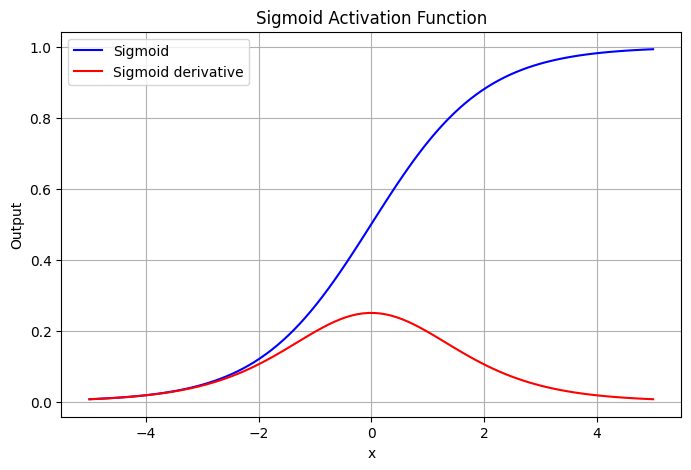

In [ ]:
# Plot the sigmoid activation function and its derivative

activation_x = np.linspace(-5, 5, 100)

plt.figure(figsize=(8, 5))
plt.plot(activation_x, sigmoid(activation_x), c="blue", label="Sigmoid")
plt.plot(activation_x, sigmoid_p(activation_x), c="red",
         label="Sigmoid derivative")
plt.xlabel("x")
plt.ylabel("Output")
plt.title("Sigmoid Activation Function")
plt.grid(True)
plt.legend()
plt.show()


Iteration 0: loss = 0.6954
Iteration 1000: loss = 0.0033
Iteration 2000: loss = 0.0015
Iteration 3000: loss = 0.0010
Iteration 4000: loss = 0.0007
Iteration 5000: loss = 0.0006
Iteration 6000: loss = 0.0005
Iteration 7000: loss = 0.0004
Iteration 8000: loss = 0.0003
Iteration 9000: loss = 0.0003


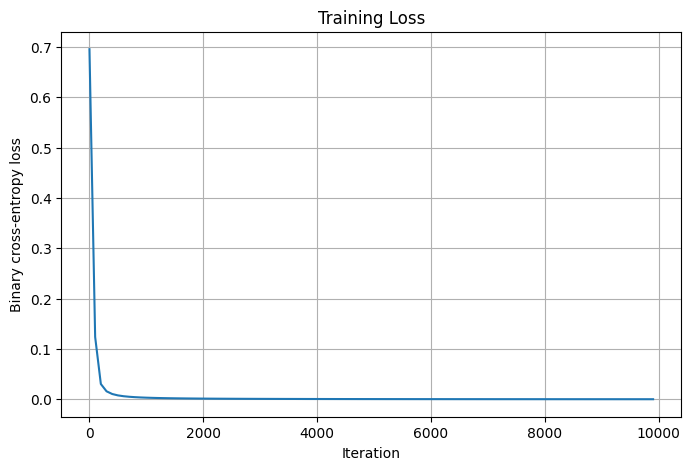

In [ ]:
# Train the neural network using backpropagation

def train(X, y, hidden_size=4, iterations=10000, learning_rate=0.5):
    np.random.seed(42)

    input_size = X.shape[1]
    output_size = 1

    # Randomly initialize weights and initialize biases to zero
    w1 = np.random.randn(input_size, hidden_size) * 0.1
    b1 = np.zeros((1, hidden_size))
    w2 = np.random.randn(hidden_size, output_size) * 0.1
    b2 = np.zeros((1, output_size))

    costs = []
    eps = 1e-8
    y_train = y.reshape(-1, 1)

    for i in range(iterations):
        # Forward propagation
        z1 = X @ w1 + b1
        a1 = sigmoid(z1)
        z2 = a1 @ w2 + b2
        a2 = sigmoid(z2)

        # Binary cross-entropy loss
        loss = -np.mean(
            y_train * np.log(a2 + eps)
            + (1 - y_train) * np.log(1 - a2 + eps)
        )

        # Backpropagation
        dz2 = (a2 - y_train) / len(X)
        dw2 = a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        da1 = dz2 @ w2.T
        dz1 = da1 * a1 * (1 - a1)
        dw1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # Update parameters
        w2 -= learning_rate * dw2
        b2 -= learning_rate * db2
        w1 -= learning_rate * dw1
        b1 -= learning_rate * db1

        if i % 100 == 0:
            costs.append(loss)

        if i % 1000 == 0:
            print(f"Iteration {i}: loss = {loss:.4f}")

    return costs, w1, b1, w2, b2

costs, W1, b1, W2, b2 = train(X, y)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(len(costs)) * 100, costs)
plt.xlabel("Iteration")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()


In [ ]:
# Predict the class of the mystery sentence

mystery_tokens = mystery_text.lower().split()
mystery_vector = np.zeros((1, len(vocabulary)), dtype=float)

for word in mystery_tokens:
    if word in word_to_id:
        mystery_vector[0, word_to_id[word]] = 1.0

# Forward propagation
hidden_output = sigmoid(mystery_vector @ W1 + b1)
probability = sigmoid(hidden_output @ W2 + b2)[0, 0]
prediction = int(probability >= 0.5)

print("Mystery sentence:", mystery_text)
print(f"Probability of class 1 (sports): {probability:.4f}")
print("Predicted class:", prediction)
print("Predicted label:", "Sports / Football" if prediction == 1
      else "Reading / Studying")

# Check predictions on the training data
train_hidden = sigmoid(X @ W1 + b1)
train_probabilities = sigmoid(train_hidden @ W2 + b2)
train_predictions = (train_probabilities >= 0.5).astype(int)

print("\nActual labels:", y.flatten().astype(int))
print("Predicted labels:", train_predictions.flatten())
print(f"Training accuracy: {np.mean(train_predictions == y) * 100:.2f}%")


Mystery sentence: I like playing football
Probability of class 1 (sports): 0.9976
Predicted class: 1
Predicted label: Sports / Football

Actual labels: [1 0 1 0 1 0 1 0]
Predicted labels: [1 0 1 0 1 0 1 0]
Training accuracy: 100.00%
